Setup, folder, utilitas

In [2]:
import re, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 200)
sns.set_theme(style="whitegrid", context="notebook")

BASE = Path(r"C:\Users\Zerlina\Documents\PENS\SEMESTER 5\project analitika data\AgriDash-0.1")

DIRS = {
    "raw": BASE / "data" / "raw" / "biofarmaka",
    "clean": BASE / "data" / "clean" / "biofarmaka",
    "model_ready": BASE / "data" / "model_ready",
    "eda": BASE / "outputs" / "eda",
    "reports": BASE / "outputs" / "reports",
}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

FILES = {
    "luas_kab": "Luas_Panen_Biofarmaka.csv",
    "prod_kab": "Total_Produksi_Biofarmaka.csv",
    "luas_kec": "Luas_Panen_Biofarmaka_per_kecamatan.csv",
    "prod_kec": "Total_Produksi_Biofarmaka_per_kecamatan.csv",
}
missing = [f for f in FILES.values() if not (DIRS["raw"] / f).exists()]
print("File mentah lengkap" if not missing else f"File belum ada di {DIRS['raw']}: {missing}")

def savefig(name):
    plt.tight_layout(); plt.savefig(DIRS["eda"] / f"{name}.png", dpi=150, bbox_inches="tight"); plt.show()

File mentah lengkap


Baca data mentah sebagai teks 

In [ ]:
raw = {
    k: pd.read_csv(
        DIRS["biofarmaka"] / f,
        dtype=str,
        encoding="utf-8-sig",
        keep_default_na=False
    )
    for k, f in FILES.items()
}

for k, d in raw.items():
    d.columns = d.columns.str.strip()
    print(f"\n ## {k} | {FILES[k]} | shape={d.shape}")
    display(d.head(8))


 ## luas_kab | Luas_Panen_Biofarmaka.csv | shape=(96, 3)


,Tahun,Jenis Tanaman,Luas Panen Tanaman Biofarmaka
0,2020,Jahe/Ginger(m2),78290
1,2020,Kapulaga/Java Cardamom(m2),4888
2,2020,Keji Beling/Verbenaceae(m2),125
3,2020,Kencur/East Indian Galangal(m2),1056
4,2020,Kunyit/Turmeric(m2),4710676
5,2020,Laos/Lengkuas/Galanga(m2),3503
6,2020,Lempuyang/Zingiber Aromaticum(m2),-
7,2020,Lidah Buaya/Aloevera(m2),1451



 ## prod_kab | Total_Produksi_Biofarmaka.csv | shape=(96, 3)


,Tahun,Jenis Tanaman,Produksi Tanaman Biofarmaka
0,2020,Jahe/Ginger(kg),359025
1,2020,Kapulaga/Java Cardamom(kg),138850
2,2020,Keji Beling/Verbenaceae(kg),4761
3,2020,Kencur/East Indian Galangal(kg),47420
4,2020,Kunyit/Turmeric(kg),13678918
5,2020,Laos/Lengkuas/Galanga(kg),36972
6,2020,Lempuyang/Zingiber Aromaticum(kg),3608
7,2020,Lidah Buaya/Aloevera(kg),117390



 ## luas_kec | Luas_Panen_Biofarmaka_per_kecamatan.csv | shape=(162, 18)


,Tahun,Kecamatan,Luas Panen Jahe (meter persegi) (M2),Luas Panen Kapulaga (meter persegi) (M2),Luas Panen Keji Beling (meter persegi) (M2),Luas Panen Kencur (meter persegi) (M2),Luas Panen Kunyit (meter persegi) (M2),Luas Panen Laos/Lengkuas (meter persegi) (M2),Luas Panen Lempuyang (meter persegi) (M2),Luas Panen Lidah Buaya (meter persegi) (M2),Luas Panen Mahkota Dewa (pohon) (Pohon),Luas Panen Mengkudu/Pace (pohon) (Pohon),Luas Panen Sambiloto (meter persegi) (M2),Luas Panen Temuireng (meter persegi) (M2),Luas Panen Temukunci (meter persegi) (M2),Luas Panen Temulawak (meter persegi) (M2),Luas Panen Jeruk Nipis (pohon) (Pohon),Luas Panen Serai (meter persegi) (Pohon)
0,2020,Badas,11443,1233,59,370,469249,340,38,694,71,100,67,58,66,130596,1291,726
1,2021,Badas,10084,1204,58,335,495264,303,35,630,79,88,62,60,61,127605,1374,777
2,2022,Badas,9402,1060,60,357,581093,297,33,591,84,102,60,56,59,126078,1566,899
3,2023,Badas,10847,995,59,374,525518,343,36,536,74,115,66,56,53,143625,1596,1015
4,2024,Badas,12578,-,-,398,595338,-,33,484,70,114,67,50,53,-,1418,1088
5,2025,Badas,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-
6,2020,Banyakan,14837,2240,21,279,4401888,721,51,996,30,141,57,38,42,1102974,795,621
7,2021,Banyakan,13657,2357,23,247,4347459,709,59,923,27,159,53,40,40,981302,902,629



 ## prod_kec | Total_Produksi_Biofarmaka_per_kecamatan.csv | shape=(162, 18)


,Tahun,Kecamatan,Produksi Jahe (kilogram) (Kg),Produksi Kapulaga (kilogram) (Kg),Produksi Keji Beling (kilogram) (Kg),Produksi Kencur (kilogram) (Kg),Produksi Kunyit (kilogram) (Kg),Produksi Laos/Lengkuas (kilogram) (Kg),Produksi Lempuyang (kilogram) (Kg),Produksi Lidah Buaya (kilogram) (Kg),Produksi Mahkota Dewa (kilogram) (Kg),Produksi Mengkudu/Pace (kilogram) (Kg),Produksi Sambiloto (kilogram) (Kg),Produksi Temuireng (kilogram) (Kg),Produksi Temukunci (kilogram) (Kg),Produksi Temulawak (kilogram) (Kg),Produksi Jeruk Nipis (kilogram) (Kg),Produksi Serai (kilogram) (Kg)
0,2020,Badas,16714,5680,210,1587,196801,1018,155,4721,199,2281,90,339,130,77798,33955,6102
1,2021,Badas,14718,5149,219,1467,187629,1078,170,4493,182,2262,102,306,117,67811,35079,7147
2,2022,Badas,13255,5555,241,1370,194969,1184,163,4270,163,2245,108,300,129,77625,31403,7127
3,2023,Badas,13284,6380,236,1252,209188,1141,179,4401,163,2131,120,-,151,69080,34213,7045
4,2024,Badas,15517,6073,211,-,185745,1259,175,4136,156,1974,114,-,169,70579,38660,-
5,2025,Badas,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-,-
6,2020,Banyakan,2808,3172,212,2187,4455917,2593,112,2093,99,716,179,355,170,724190,6283,14406
7,2021,Banyakan,3129,2772,230,2311,4197851,2524,115,1944,87,719,183,330,157,767465,6128,14047


 Inspeksi: info, describe, missing, duplikat, konsistensi

In [43]:
def to_num(s):
    return pd.to_numeric(s.astype(str).str.replace(",", "", regex=False).str.strip(), errors="coerce")

inspection = {}
for k, d in raw.items():
    print(f"\n{'-'*90}\n{k}: {d.shape[0]} baris x {d.shape[1]} kolom")
    val_cols = [c for c in d.columns if c not in ("Tahun", "Jenis Tanaman", "Kecamatan")]
    tokens = {tok: int((d[val_cols] == tok).sum().sum()) for tok in ["-", "...", ""]}
    non_numeric = d[val_cols].apply(lambda s: s[to_num(s).isna() & ~s.isin(["-", "...", ""])])
    numeric = d[val_cols].apply(to_num)
    key_cols = [c for c in ("Tahun", "Jenis Tanaman", "Kecamatan") if c in d.columns]
    inspection[k] = {
        "baris": d.shape[0], "kolom": d.shape[1],
        "token_-": tokens["-"], "token_...": tokens["..."], "token_kosong": tokens[""],
        "duplikat_baris": int(d.duplicated().sum()),
        "duplikat_kunci": int(d.duplicated(subset=key_cols).sum()),
        "nilai_non_numerik_lain": int(non_numeric.notna().sum().sum()),
        "nilai_negatif": int((numeric < 0).sum().sum()),
        "nilai_nol": int((numeric == 0).sum().sum()),
        "tahun": sorted(d["Tahun"].unique().tolist()),
    }
    print(pd.Series(inspection[k]).to_string())
    print("\nTipe data (sebelum konversi):"); print(d.dtypes.value_counts().to_string())
    d.info()
    print("\nStatistik deskriptif (setelah konversi numerik, '-' dan '...' menjadi NaN):")
    display(numeric.describe().T)

print("\nKecamatan (luas) :", sorted(raw["luas_kec"]["Kecamatan"].unique()))
print("Kecamatan sama di file luas & produksi:",
      set(raw["luas_kec"]["Kecamatan"]) == set(raw["prod_kec"]["Kecamatan"]))
print("Spasi ganda / spasi tepi:", {k: int(d.select_dtypes(include=["object", "string"]).apply(lambda s: s.str.contains(r"^\s|\s$|\s{2,}")).sum().sum()) for k, d in raw.items()})
print("\nJenis tanaman (agregat luas):"); print(raw["luas_kab"]["Jenis Tanaman"].unique())


------------------------------------------------------------------------------------------
luas_kab: 96 baris x 3 kolom
baris                                                       96
kolom                                                        3
token_-                                                     16
token_...                                                    3
token_kosong                                                 0
duplikat_baris                                               0
duplikat_kunci                                               0
nilai_non_numerik_lain                                       0
nilai_negatif                                                0
nilai_nol                                                    0
tahun                     [2020, 2021, 2022, 2023, 2024, 2025]

Tipe data (sebelum konversi):
str    3
<class 'pandas.DataFrame'>
RangeIndex: 96 entries, 0 to 95
Data columns (total 3 columns):
 #   Column                         Non-Null Count  Dty

,count,mean,std,min,25%,50%,75%,max
Luas Panen Tanaman Biofarmaka,77.0,410326.012987,1.183568e+06,30.0,801.0,3504.0,19008.0,4753652.0



------------------------------------------------------------------------------------------
prod_kab: 96 baris x 3 kolom
baris                                                       96
kolom                                                        3
token_-                                                      4
token_...                                                    1
token_kosong                                                 0
duplikat_baris                                               0
duplikat_kunci                                               0
nilai_non_numerik_lain                                       0
nilai_negatif                                                0
nilai_nol                                                    0
tahun                     [2020, 2021, 2022, 2023, 2024, 2025]

Tipe data (sebelum konversi):
str    3
<class 'pandas.DataFrame'>
RangeIndex: 96 entries, 0 to 95
Data columns (total 3 columns):
 #   Column                       Non-Null Count  Dtype

,count,mean,std,min,25%,50%,75%,max
Produksi Tanaman Biofarmaka,91.0,1.041964e+06,3.092518e+06,29.0,4754.0,40967.0,245127.0,14014286.0



------------------------------------------------------------------------------------------
luas_kec: 162 baris x 18 kolom
baris                                                      162
kolom                                                       18
token_-                                                    457
token_...                                                    0
token_kosong                                                 0
duplikat_baris                                               0
duplikat_kunci                                               0
nilai_non_numerik_lain                                       0
nilai_negatif                                                0
nilai_nol                                                    0
tahun                     [2020, 2021, 2022, 2023, 2024, 2025]

Tipe data (sebelum konversi):
str    18
<class 'pandas.DataFrame'>
RangeIndex: 162 entries, 0 to 161
Data columns (total 18 columns):
 #   Column                                      

,count,mean,std,min,25%,50%,75%,max
Luas Panen Jahe (meter persegi) (M2),137.0,14700.773723,1.919612e+04,32.0,4383.00,11443.0,14970.00,94998.0
Luas Panen Kapulaga (meter persegi) (M2),133.0,1952.939850,1.269304e+03,4.0,1115.00,1609.0,2448.00,5802.0
Luas Panen Keji Beling (meter persegi) (M2),126.0,46.500000,1.763576e+01,20.0,33.00,43.0,61.00,91.0
Luas Panen Kencur (meter persegi) (M2),132.0,410.666667,2.413554e+02,17.0,267.00,372.5,469.25,1146.0
Luas Panen Kunyit (meter persegi) (M2),136.0,815100.647059,1.231937e+06,1.0,268924.25,617979.5,724877.25,6030781.0
Luas Panen Laos/Lengkuas (meter persegi) (M2),132.0,688.416667,5.828925e+02,2.0,392.50,509.0,888.50,3504.0
Luas Panen Lempuyang (meter persegi) (M2),130.0,42.900000,1.584804e+01,19.0,28.00,41.0,56.00,78.0
Luas Panen Lidah Buaya (meter persegi) (M2),131.0,913.412214,3.284621e+02,316.0,653.50,904.0,1114.00,1777.0
Luas Panen Mahkota Dewa (pohon) (Pohon),132.0,49.901515,2.052809e+01,16.0,32.00,45.5,69.00,91.0
Luas Panen Mengkudu/Pace (pohon) (Pohon),137.0,214.532847,1.630452e+02,32.0,115.00,189.0,234.00,802.0



------------------------------------------------------------------------------------------
prod_kec: 162 baris x 18 kolom
baris                                                      162
kolom                                                       18
token_-                                                    452
token_...                                                    0
token_kosong                                                 0
duplikat_baris                                               0
duplikat_kunci                                               0
nilai_non_numerik_lain                                       0
nilai_negatif                                                0
nilai_nol                                                    0
tahun                     [2020, 2021, 2022, 2023, 2024, 2025]

Tipe data (sebelum konversi):
str    18
<class 'pandas.DataFrame'>
RangeIndex: 162 entries, 0 to 161
Data columns (total 18 columns):
 #   Column                                  Non-

,count,mean,std,min,25%,50%,75%,max
Produksi Jahe (kilogram) (Kg),140.0,2.540597e+04,6.158210e+04,23.0,4980.50,9819.0,15869.75,359025.0
Produksi Kapulaga (kilogram) (Kg),132.0,1.041932e+04,2.480647e+04,13.0,3346.50,5226.0,6751.00,138850.0
Produksi Keji Beling (kilogram) (Kg),132.0,3.532273e+02,8.641168e+02,40.0,135.75,198.0,236.25,4922.0
Produksi Kencur (kilogram) (Kg),135.0,3.488756e+03,8.443641e+03,146.0,1004.00,1648.0,2483.50,47420.0
Produksi Kunyit (kilogram) (Kg),139.0,1.042088e+06,2.562786e+06,4.0,177809.00,362682.0,659585.00,14014286.0
Produksi Laos/Lengkuas (kilogram) (Kg),138.0,2.790014e+03,6.666598e+03,4.0,804.00,1195.0,1807.75,37391.0
Produksi Lempuyang (kilogram) (Kg),131.0,2.876947e+02,7.003264e+02,43.0,87.50,151.0,189.50,3975.0
Produksi Lidah Buaya (kilogram) (Kg),130.0,8.663154e+03,2.059959e+04,1117.0,2730.75,4037.0,6323.75,117390.0
Produksi Mahkota Dewa (kilogram) (Kg),131.0,3.007634e+02,7.313981e+02,66.0,100.50,156.0,205.00,4163.0
Produksi Mengkudu/Pace (kilogram) (Kg),136.0,2.985294e+03,7.261040e+03,53.0,792.75,1453.0,1838.25,41559.0



Kecamatan (luas) : ['Badas', 'Banyakan', 'Gampengrejo', 'Grogol', 'Gurah', 'Kandangan', 'Kandat', 'Kayen Kidul', 'Kediri', 'Kepung', 'Kras', 'Kunjang', 'Mojo', 'Ngadiluwih', 'Ngancar', 'Ngasem', 'Pagu', 'Papar', 'Pare', 'Plemahan', 'Plosoklaten', 'Puncu', 'Purwoasri', 'Ringinrejo', 'Semen', 'Tarokan', 'Wates']
Kecamatan sama di file luas & produksi: True
Spasi ganda / spasi tepi: {'luas_kab': 0, 'prod_kab': 0, 'luas_kec': 0, 'prod_kec': 0}

Jenis tanaman (agregat luas):
<StringArray>
[                             'Jahe/Ginger(m2)',                   'Kapulaga/Java Cardamom(m2)',                  'Keji Beling/Verbenaceae(m2)',              'Kencur/East Indian Galangal(m2)',
                          'Kunyit/Turmeric(m2)',                    'Laos/Lengkuas/Galanga(m2)',            'Lempuyang/Zingiber Aromaticum(m2)',                     'Lidah Buaya/Aloevera(m2)',
 'Mahkota Dewa/Phaleria Macrocarpa(pohon/tree)',    'Mengkudu/Pace/Indian Mulberry(pohon/tree)',                 'Sambiloto/

Standardisasi nama dan wide → long

In [44]:
def komoditas_key(text):
    """'Laos/Lengkuas/Galanga(m2)' -> 'laos' ; 'Produksi Mengkudu/Pace (kilogram) (Kg)' -> 'mengkudu'"""
    t = re.sub(r"^(Luas Panen|Produksi)\s+", "", text.strip())
    t = re.split(r"\(", t)[0].strip()
    return re.sub(r"\s+", "_", t.split("/")[0].strip().lower())

def unit_from_label(text):
    m = re.findall(r"\(([^()]*)\)", text)
    return m[-1].lower() if m else None

def status_from_token(tok):
    return {"-": "strip_(nihil/tidak_ada)", "...": "titik3_(tidak_tersedia)", "": "kosong"}.get(tok, "ada")

def tidy_kab(df, value_name):
    return pd.DataFrame({
        "tahun": df["Tahun"].astype(int),
        "komoditas": df["Jenis Tanaman"].map(komoditas_key),
        "label_unit": df["Jenis Tanaman"].map(unit_from_label),
        value_name: to_num(df.iloc[:, 2]),
        f"{value_name}_status": df.iloc[:, 2].map(status_from_token),
    })
luas_kab = tidy_kab(raw["luas_kab"], "luas")
prod_kab = tidy_kab(raw["prod_kab"], "produksi")
kab = luas_kab.merge(prod_kab.drop(columns="label_unit"), on=["tahun", "komoditas"], how="outer", validate="1:1")
kab = kab.rename(columns={"label_unit": "unit_luas"})
kab["unit_luas"] = kab["unit_luas"].replace({"pohon/tree": "pohon"})

def tidy_kec(df, value_name):
    val_cols = [c for c in df.columns if c not in ("Tahun", "Kecamatan")]
    long = df.melt(id_vars=["Tahun", "Kecamatan"], value_vars=val_cols, var_name="kolom_asal", value_name="raw")
    long = long.rename(columns={"Tahun": "tahun", "Kecamatan": "kecamatan"})
    long["tahun"] = long["tahun"].astype(int)
    long["kecamatan"] = long["kecamatan"].str.strip().str.title()
    long["komoditas"] = long["kolom_asal"].map(komoditas_key)
    long[value_name] = to_num(long["raw"])
    long[f"{value_name}_status"] = long["raw"].map(status_from_token)
    long["label_unit_kec"] = long["kolom_asal"].map(unit_from_label)
    return long.drop(columns=["raw", "kolom_asal"])
luas_kec = tidy_kec(raw["luas_kec"], "luas")
prod_kec = tidy_kec(raw["prod_kec"], "produksi")
kec = luas_kec.merge(prod_kec.drop(columns="label_unit_kec"), on=["tahun", "kecamatan", "komoditas"], how="outer", validate="1:1")

unit_map = kab.drop_duplicates("komoditas").set_index("komoditas")["unit_luas"]
kec["unit_luas"] = kec["komoditas"].map(unit_map)


unit_conflict_raw = (kec.drop_duplicates("komoditas")
                        .assign(label_kec=lambda x: x["label_unit_kec"].str.lower())
                        .query("label_kec != unit_luas")[["komoditas", "unit_luas", "label_unit_kec"]])


UNIT_CONFIRMED = {"serai": "m2"}
for df_ in (kab, kec):
    df_["unit_luas"] = df_["komoditas"].map(UNIT_CONFIRMED).fillna(df_["unit_luas"])
kec["label_unit_kec"] = kec["komoditas"].map(UNIT_CONFIRMED).fillna(kec["label_unit_kec"])

unit_conflict = (kec.drop_duplicates("komoditas")
                    .assign(label_kec=lambda x: x["label_unit_kec"].str.lower())
                    .query("label_kec != unit_luas")[["komoditas", "unit_luas", "label_unit_kec"]])
print("Komoditas:", sorted(kec["komoditas"].unique()), "| jumlah =", kec["komoditas"].nunique())
print("Komoditas sama antar file agregat/kecamatan:", set(kab["komoditas"]) == set(kec["komoditas"]))

Komoditas: ['jahe', 'jeruk_nipis', 'kapulaga', 'keji_beling', 'kencur', 'kunyit', 'laos', 'lempuyang', 'lidah_buaya', 'mahkota_dewa', 'mengkudu', 'sambiloto', 'serai', 'temuireng', 'temukunci', 'temulawak'] | jumlah = 16
Komoditas sama antar file agregat/kecamatan: True


 Deteksi baris total kabupaten dan rekonsiliasi antar file (diuji dari data, tidak diasumsikan)

In [45]:
winner = (kec.dropna(subset=["produksi"]).loc[lambda d: d.groupby(["tahun", "komoditas"])["produksi"].idxmax()]["kecamatan"]
          .value_counts())
print("Wilayah dengan produksi terbesar per (tahun, komoditas):"); print(winner.head(3).to_string())
TOTAL_ROW = winner.index[0]
others = kec[kec["kecamatan"] != TOTAL_ROW]

def recon(value):
    s = others.groupby(["tahun", "komoditas"])[value].sum(min_count=1)
    t = kec[kec["kecamatan"] == TOTAL_ROW].set_index(["tahun", "komoditas"])[value]
    a = kab.set_index(["tahun", "komoditas"])[value]
    r = pd.concat({"sum_kecamatan": s, "baris_total": t, "agregat_kab": a}, axis=1).dropna()
    r["rasio_sum/total"] = r["sum_kecamatan"] / r["baris_total"]
    r["rasio_total/agregat"] = r["baris_total"] / r["agregat_kab"]
    return r
rec_prod, rec_luas = recon("produksi"), recon("luas")
print(f"\nBaris '{TOTAL_ROW}' dianggap total jika sum kecamatan ≈ baris total.")
print("Produksi - median rasio sum_kecamatan/baris_total per tahun:"); print(rec_prod.groupby("tahun")["rasio_sum/total"].median().round(3).to_string())
print("Luas     - median rasio sum_kecamatan/baris_total per tahun:"); print(rec_luas.groupby("tahun")["rasio_sum/total"].median().round(3).to_string())
print("Produksi - median rasio baris_total/agregat_kab per tahun:"); print(rec_prod.groupby("tahun")["rasio_total/agregat"].median().round(3).to_string())
print("Luas     - median rasio baris_total/agregat_kab per tahun:"); print(rec_luas.groupby("tahun")["rasio_total/agregat"].median().round(3).to_string())

kec_total = kec[kec["kecamatan"] == TOTAL_ROW].copy()   # disimpan terpisah
kec = others.copy()
print(f"\nJumlah kecamatan setelah baris total dikeluarkan: {kec['kecamatan'].nunique()}")

Wilayah dengan produksi terbesar per (tahun, komoditas):
kecamatan
Kediri    91

Baris 'Kediri' dianggap total jika sum kecamatan ≈ baris total.
Produksi - median rasio sum_kecamatan/baris_total per tahun:
tahun
2020    1.0
2021    1.0
2022    1.0
2023    1.0
2024    1.0
2025    1.0
Luas     - median rasio sum_kecamatan/baris_total per tahun:
tahun
2020    7.441
2021    6.429
2022    8.071
2023    6.431
2024    6.627
2025    1.000
Produksi - median rasio baris_total/agregat_kab per tahun:
tahun
2020    1.0
2021    1.0
2022    1.0
2023    1.0
2024    1.0
2025    1.0
Luas     - median rasio baris_total/agregat_kab per tahun:
tahun
2020    0.976
2021    0.991
2022    0.982
2023    1.097
2024    1.013
2025    1.000

Jumlah kecamatan setelah baris total dikeluarkan: 26


Kelengkapan data per tahun dan pola missing

Proporsi sel terisi (kecamatan x komoditas) per tahun:


,lengkap_luas,lengkap_prod,rasio_vs_tahun_terbaik
tahun,,,
2020,1.000,1.000,1.000
2021,1.000,1.000,1.000
2022,1.000,0.998,0.999
2023,0.971,0.971,0.971
2024,0.822,0.837,0.829
2025,0.120,0.120,0.120


Tahun dipakai untuk pemodelan: [2020, 2021, 2022, 2023, 2024] | tahun belum lengkap: [2025]
Ringkasan missing values per tahun dan komoditas:


,tahun,komoditas,n,luas_kosong,produksi_kosong
0,2020,jahe,26,0,0
1,2020,jeruk_nipis,26,0,0
2,2020,kapulaga,26,0,0
3,2020,keji_beling,26,0,0
4,2020,kencur,26,0,0
5,2020,kunyit,26,0,0
6,2020,laos,26,0,0
7,2020,lempuyang,26,0,0
8,2020,lidah_buaya,26,0,0
9,2020,mahkota_dewa,26,0,0


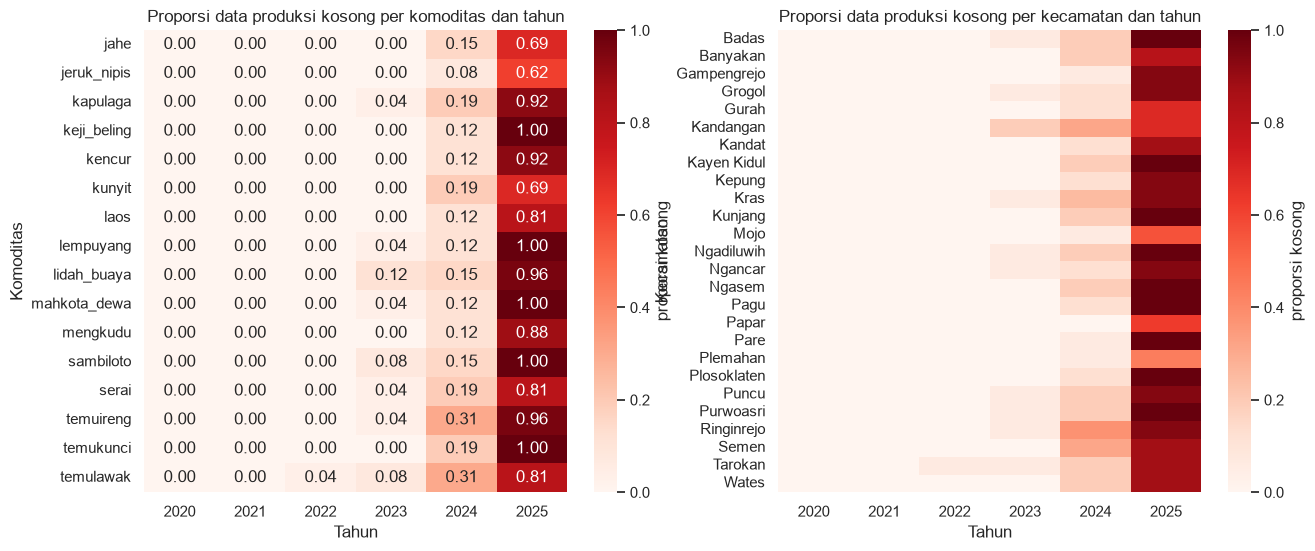

In [46]:
kec["lengkap_luas"] = kec["luas"].notna(); kec["lengkap_prod"] = kec["produksi"].notna()
cov = kec.groupby("tahun")[["lengkap_luas", "lengkap_prod"]].mean().round(3)
cov["rasio_vs_tahun_terbaik"] = (cov.mean(axis=1) / cov.mean(axis=1).max()).round(3)
print("Proporsi sel terisi (kecamatan x komoditas) per tahun:"); display(cov)
COMPLETE_YEARS = cov.index[cov["rasio_vs_tahun_terbaik"] >= 0.5].tolist()
INCOMPLETE_YEARS = [y for y in cov.index if y not in COMPLETE_YEARS]
print("Tahun dipakai untuk pemodelan:", COMPLETE_YEARS, "| tahun belum lengkap:", INCOMPLETE_YEARS)

miss_year_kom = kec.assign(kosong=lambda d: d["produksi"].isna()).pivot_table(index="komoditas", columns="tahun", values="kosong", aggfunc="mean")
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(miss_year_kom, annot=True, fmt=".2f", cmap="Reds", ax=ax[0], cbar_kws={"label": "proporsi kosong"})
ax[0].set_title("Proporsi data produksi kosong per komoditas dan tahun"); ax[0].set_xlabel("Tahun"); ax[0].set_ylabel("Komoditas")
miss_kec = kec.assign(kosong=lambda d: d["produksi"].isna()).pivot_table(index="kecamatan", columns="tahun", values="kosong", aggfunc="mean")
sns.heatmap(miss_kec, cmap="Reds", ax=ax[1], cbar_kws={"label": "proporsi kosong"})
ax[1].set_title("Proporsi data produksi kosong per kecamatan dan tahun"); ax[1].set_xlabel("Tahun"); ax[1].set_ylabel("Kecamatan")
def savefig(name):
    plt.tight_layout()
    plt.show()

miss_report = (
    kec.groupby(["tahun", "komoditas"])
    .agg(
        n=("produksi", "size"),
        luas_kosong=("luas", lambda s: s.isna().sum()),
        produksi_kosong=("produksi", lambda s: s.isna().sum())
    )
    .reset_index()
)

print("Ringkasan missing values per tahun dan komoditas:")
display(miss_report)

Fitur turunan (lag dan YoY hanya dari tahun sebelumnya, tanpa informasi masa depan)

In [47]:
kec = kec.sort_values(["kecamatan", "komoditas", "tahun"]).reset_index(drop=True)
kec["produktivitas"] = np.where((kec["luas"] > 0) & kec["produksi"].notna(), kec["produksi"] / kec["luas"], np.nan)  # kg/m2 atau kg/pohon
grp = kec.groupby(["kecamatan", "komoditas"], sort=False)
for c in ["luas", "produksi", "produktivitas"]:
    kec[f"{c}_lag1"] = grp[c].shift(1)
    kec[f"{c}_yoy"] = (kec[c] - kec[f"{c}_lag1"]) / kec[f"{c}_lag1"].replace(0, np.nan)
kab = kab.sort_values(["komoditas", "tahun"]).reset_index(drop=True)
kab["produktivitas"] = np.where(kab["luas"] > 0, kab["produksi"] / kab["luas"], np.nan)
display(kec.describe(include="all").T.head(25))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
tahun,2496.0,NaN,NaN,NaN,2022.5,1.708167,2020.0,2021.0,2022.5,2024.0,2025.0
kecamatan,2496,26,Badas,96,NaN,NaN,NaN,NaN,NaN,NaN,NaN
komoditas,2496,16,jahe,156,NaN,NaN,NaN,NaN,NaN,NaN,NaN
luas,2044.0,NaN,NaN,NaN,49674.278376,250173.628148,1.0,48.0,298.0,1426.75,4401888.0
luas_status,2496,2,ada,2044,NaN,NaN,NaN,NaN,NaN,NaN,NaN
label_unit_kec,2496,2,m2,2028,NaN,NaN,NaN,NaN,NaN,NaN,NaN
produksi,2049.0,NaN,NaN,NaN,46275.603709,258729.744634,4.0,194.0,1286.0,7111.0,4455917.0
produksi_status,2496,2,ada,2049,NaN,NaN,NaN,NaN,NaN,NaN,NaN
unit_luas,2496,2,m2,2028,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lengkap_luas,2496,2,True,2044,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Univariate: histogram, boxplot, frekuensi, outlier IQR

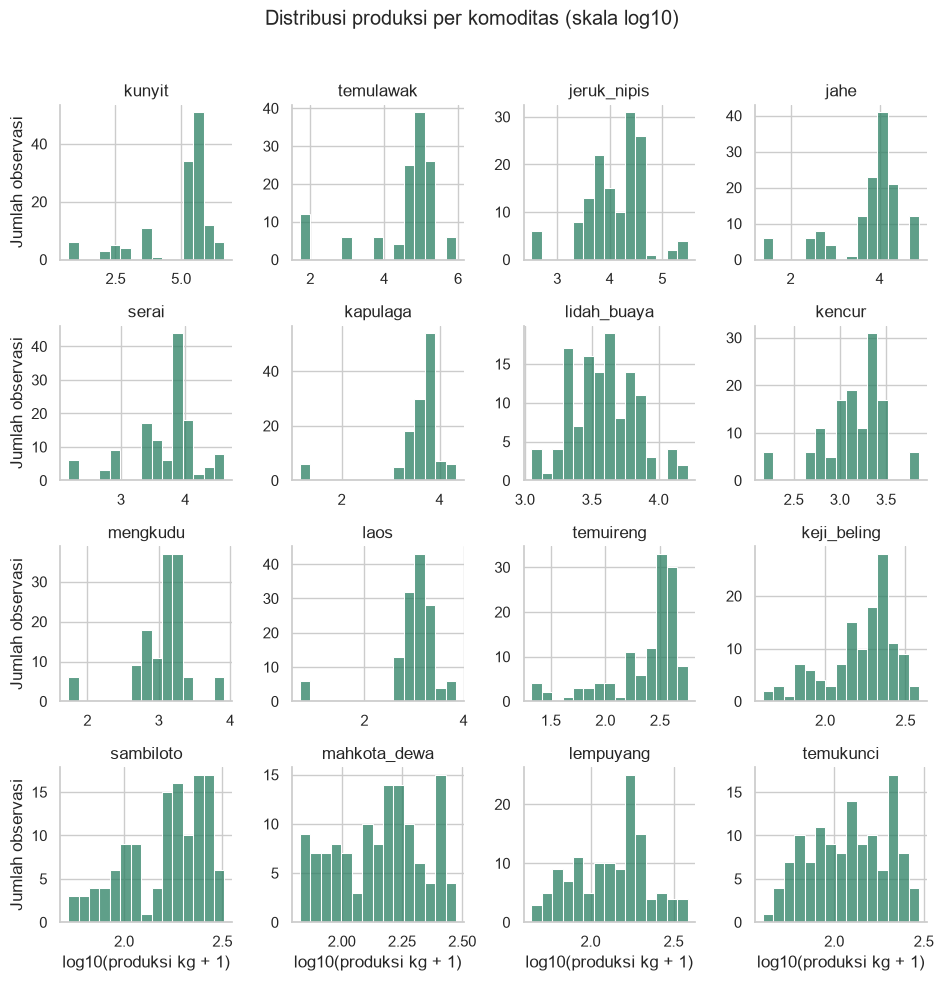

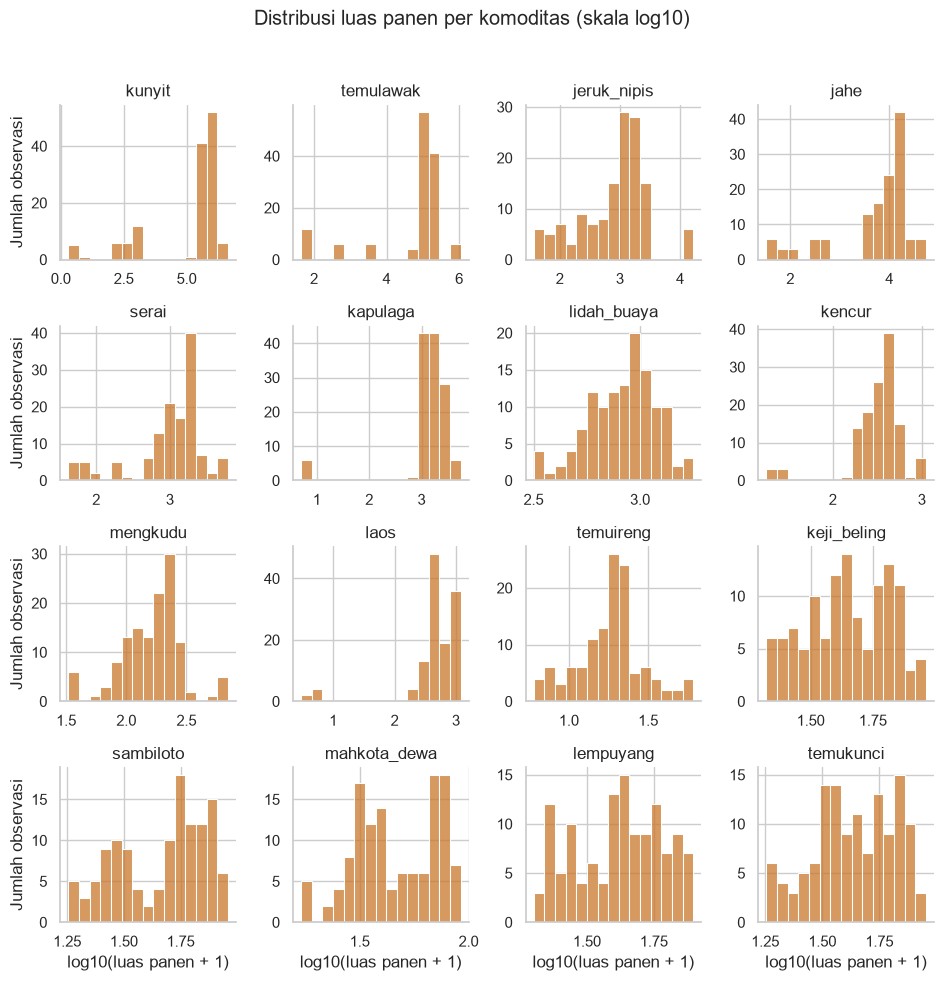

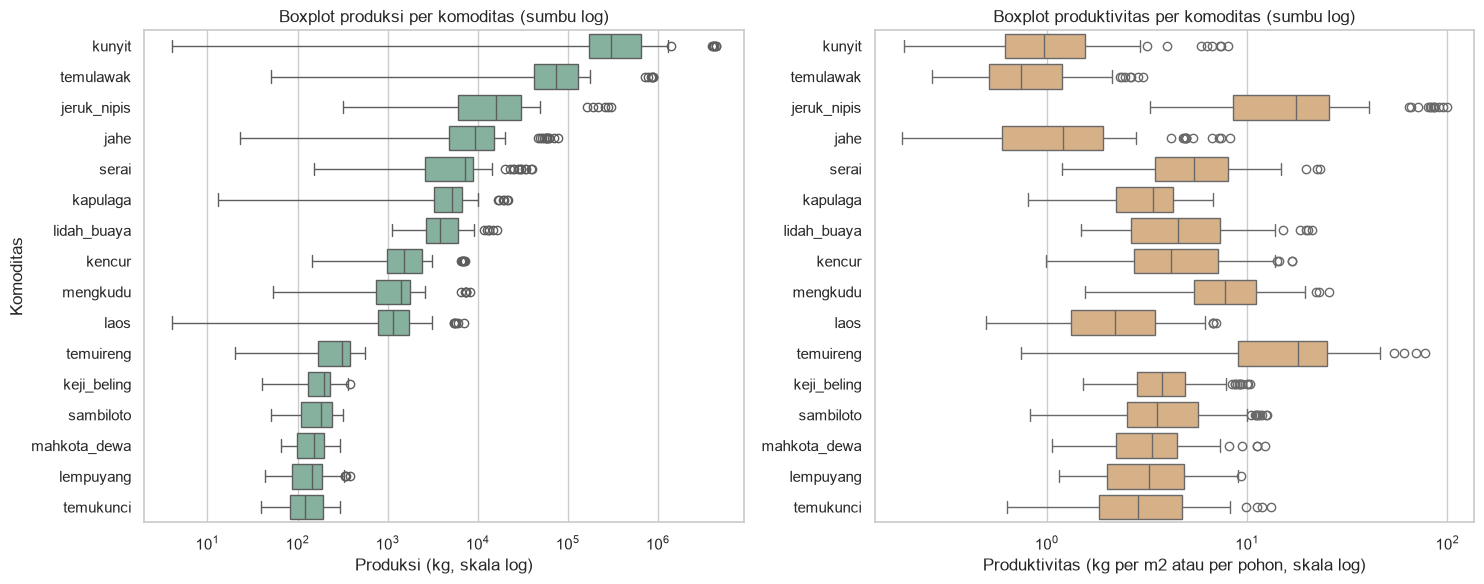

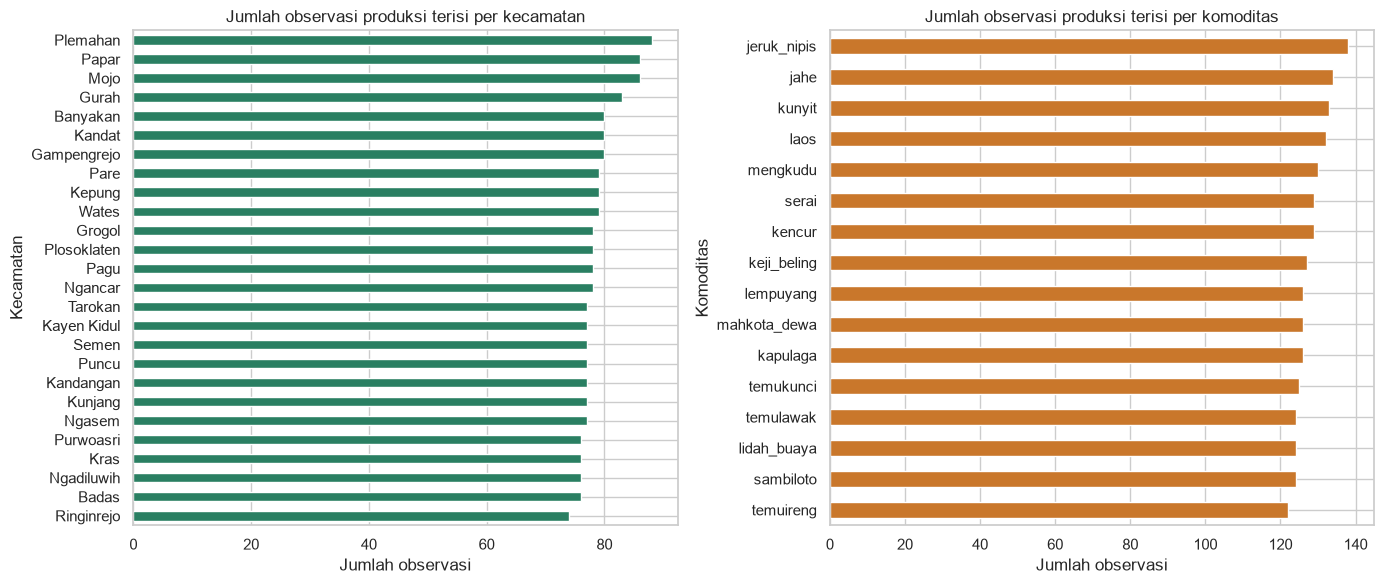

Jumlah outlier IQR (log) per komoditas:


,out_iqr_prod,out_iqr_yield
komoditas,,
jahe,21,0
jeruk_nipis,5,0
kapulaga,8,0
keji_beling,5,0
kencur,5,0
kunyit,27,2
laos,10,0
lempuyang,0,0
lidah_buaya,0,0


In [48]:
kom_order = kec.groupby("komoditas")["produksi"].median().sort_values(ascending=False).index.tolist()
g = sns.FacetGrid(kec.dropna(subset=["produksi"]).assign(log_produksi=lambda d: np.log10(d["produksi"] + 1)),
                  col="komoditas", col_wrap=4, sharex=False, sharey=False, height=2.4, col_order=kom_order)
g.map_dataframe(sns.histplot, x="log_produksi", bins=15, color="#2a7f62"); g.set_titles("{col_name}")
g.set_axis_labels("log10(produksi kg + 1)", "Jumlah observasi"); g.fig.suptitle("Distribusi produksi per komoditas (skala log10)", y=1.02)
savefig("02_hist_produksi")

g = sns.FacetGrid(kec.dropna(subset=["luas"]).assign(log_luas=lambda d: np.log10(d["luas"] + 1)),
                  col="komoditas", col_wrap=4, sharex=False, sharey=False, height=2.4, col_order=kom_order)
g.map_dataframe(sns.histplot, x="log_luas", bins=15, color="#c9772b"); g.set_titles("{col_name}")
g.set_axis_labels("log10(luas panen + 1)", "Jumlah observasi"); g.fig.suptitle("Distribusi luas panen per komoditas (skala log10)", y=1.02)
savefig("03_hist_luas")

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
sns.boxplot(data=kec, y="komoditas", x="produksi", order=kom_order, ax=ax[0], color="#7fb89f"); ax[0].set_xscale("log")
ax[0].set_title("Boxplot produksi per komoditas (sumbu log)"); ax[0].set_xlabel("Produksi (kg, skala log)"); ax[0].set_ylabel("Komoditas")
sns.boxplot(data=kec, y="komoditas", x="produktivitas", order=kom_order, ax=ax[1], color="#e3b17a"); ax[1].set_xscale("log")
ax[1].set_title("Boxplot produktivitas per komoditas (sumbu log)"); ax[1].set_xlabel("Produktivitas (kg per m2 atau per pohon, skala log)"); ax[1].set_ylabel("")
savefig("04_boxplot_produksi_produktivitas")

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
kec.dropna(subset=["produksi"]).groupby("kecamatan").size().sort_values().plot.barh(ax=ax[0], color="#2a7f62")
ax[0].set_title("Jumlah observasi produksi terisi per kecamatan"); ax[0].set_xlabel("Jumlah observasi"); ax[0].set_ylabel("Kecamatan")
kec.dropna(subset=["produksi"]).groupby("komoditas").size().sort_values().plot.barh(ax=ax[1], color="#c9772b")
ax[1].set_title("Jumlah observasi produksi terisi per komoditas"); ax[1].set_xlabel("Jumlah observasi"); ax[1].set_ylabel("Komoditas")
savefig("05_frekuensi_kategorikal")

def iqr_flag(s, k=1.5):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return (s < q1 - k * i) | (s > q3 + k * i)
base = kec[kec["tahun"].isin(COMPLETE_YEARS)].copy()
base["log_prod"] = np.log1p(base["produksi"]); base["log_yield"] = np.log(base["produktivitas"])
base["out_iqr_prod"] = base.groupby("komoditas")["log_prod"].transform(lambda s: iqr_flag(s.dropna()).reindex(s.index, fill_value=False))
base["out_iqr_yield"] = base.groupby("komoditas")["log_yield"].transform(lambda s: iqr_flag(s.dropna()).reindex(s.index, fill_value=False))
print("Jumlah outlier IQR (log) per komoditas:")
display(base.groupby("komoditas")[["out_iqr_prod", "out_iqr_yield"]].sum().astype(int))

Bivariate: luas vs produksi, korelasi

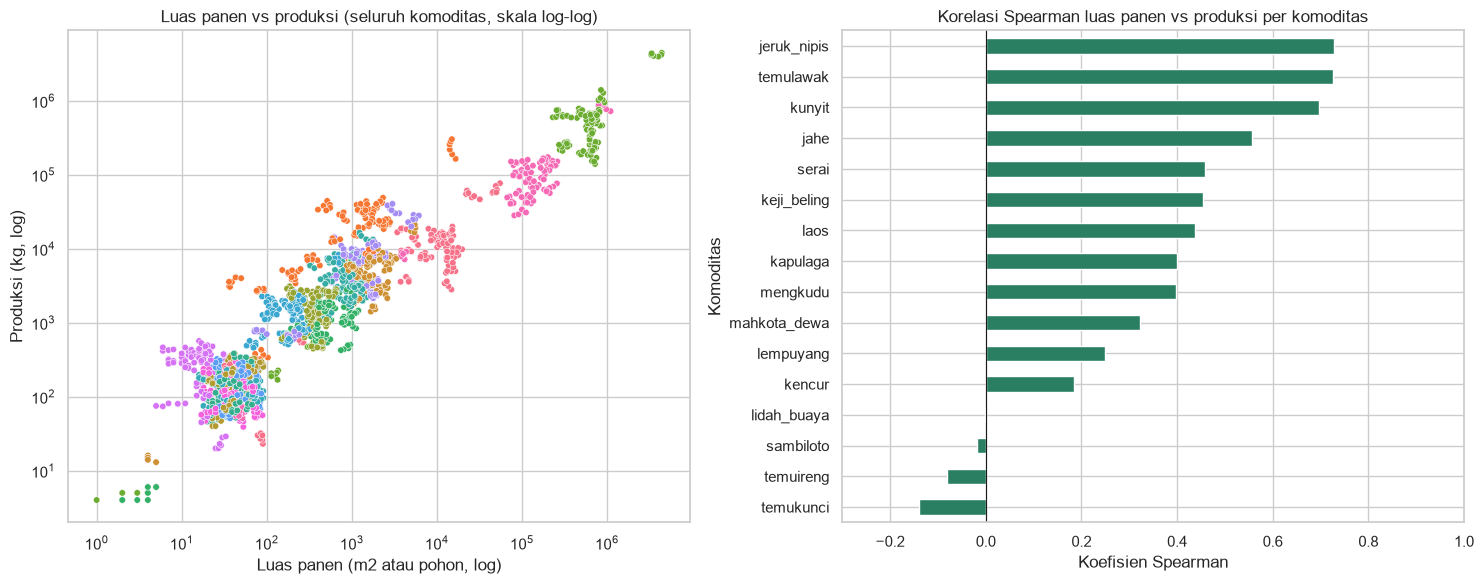

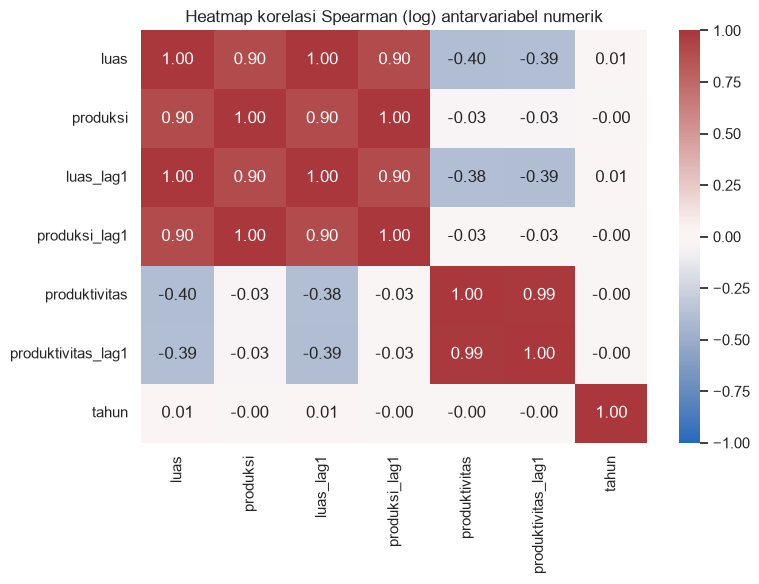

Cuaca & harga: tidak ada kolom cuaca atau harga pada keempat file -> analisis hubungan cuaca-produksi dan harga-waktu tidak dapat dilakukan.


In [49]:
sub = kec.dropna(subset=["luas", "produksi"]).query("luas > 0 and produksi > 0").copy()
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(data=sub, x="luas", y="produksi", hue="komoditas", s=22, ax=ax[0], legend=False)
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_title("Luas panen vs produksi (seluruh komoditas, skala log-log)")
ax[0].set_xlabel("Luas panen (m2 atau pohon, log)"); ax[0].set_ylabel("Produksi (kg, log)")
corr_kom = sub.groupby("komoditas").apply(lambda d: pd.Series({"n": len(d), "pearson_log": np.corrcoef(np.log(d["luas"]), np.log(d["produksi"]))[0, 1],
                                                              "spearman": d["luas"].corr(d["produksi"], method="spearman")}))
corr_kom = corr_kom.sort_values("spearman")
corr_kom["spearman"].plot.barh(ax=ax[1], color="#2a7f62"); ax[1].set_xlim(-0.3, 1); ax[1].axvline(0, c="k", lw=0.8)
ax[1].set_title("Korelasi Spearman luas panen vs produksi per komoditas"); ax[1].set_xlabel("Koefisien Spearman"); ax[1].set_ylabel("Komoditas")
savefig("06_luas_vs_produksi")

num_cols = ["luas", "produksi", "produktivitas", "luas_lag1", "produksi_lag1", "produktivitas_lag1", "tahun"]
cm = np.log1p(sub[[c for c in num_cols if c not in ("tahun", "produktivitas", "produktivitas_lag1")]]).join(
     np.log(sub[["produktivitas", "produktivitas_lag1"]])).join(sub["tahun"]).corr(method="spearman")
plt.figure(figsize=(8, 6)); sns.heatmap(cm, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1)
plt.title("Heatmap korelasi Spearman (log) antarvariabel numerik"); savefig("07_heatmap_korelasi")
print("Cuaca & harga: tidak ada kolom cuaca atau harga pada keempat file -> analisis hubungan cuaca-produksi dan harga-waktu tidak dapat dilakukan.")   

Temporal (agregat kabupaten, 2020–2025)

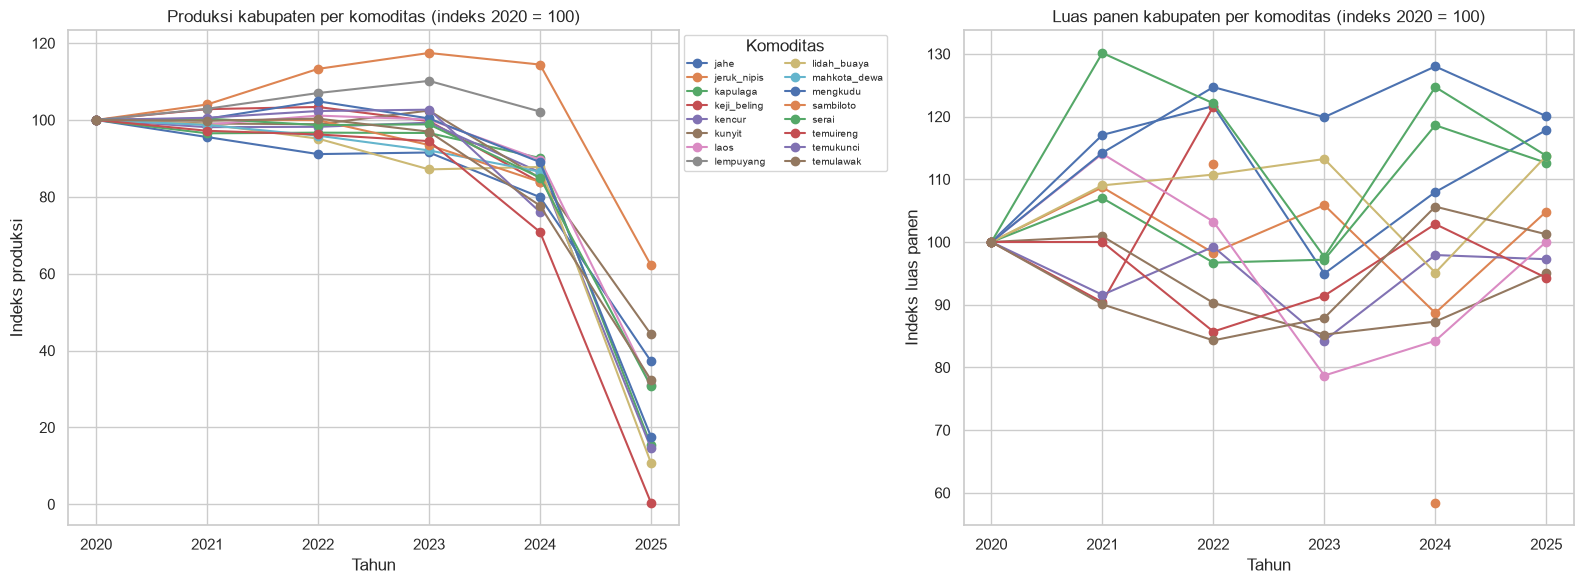

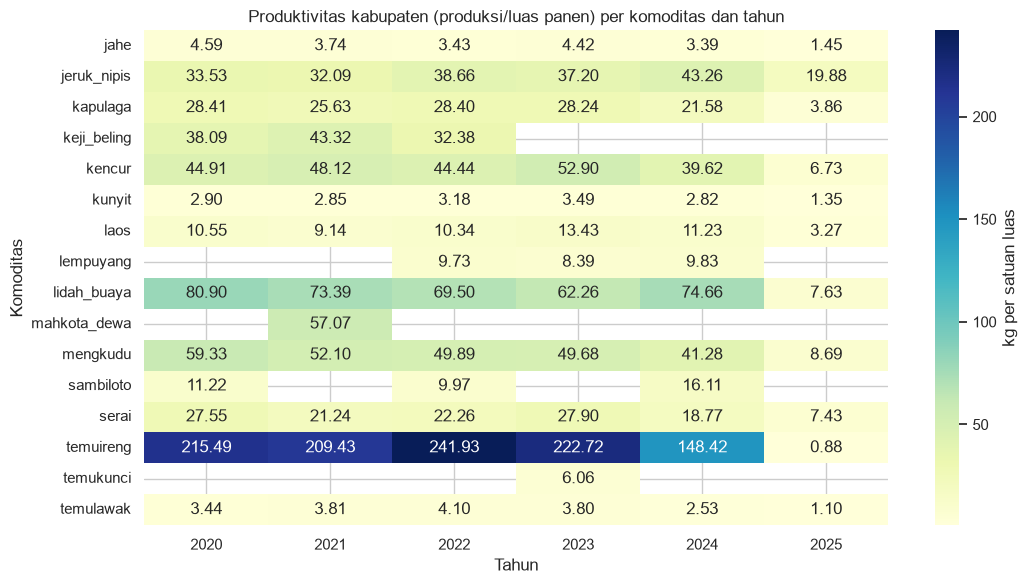

Perubahan YoY produksi kabupaten:


komoditas,jahe,jeruk_nipis,kapulaga,keji_beling,kencur,kunyit,laos,lempuyang,lidah_buaya,mahkota_dewa,mengkudu,sambiloto,serai,temuireng,temukunci,temulawak
tahun,,,,,,,,,,,,,,,,
2020,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021,-0.044,0.040,-0.035,0.028,-0.019,-0.009,-0.012,0.029,-0.011,-0.013,0.003,0.000,0.004,-0.028,0.006,-0.002
2022,-0.046,0.089,0.002,0.006,0.001,-0.002,0.023,0.040,-0.038,-0.028,0.045,-0.000,-0.017,-0.010,0.017,0.006
2023,0.005,0.037,-0.001,-0.036,0.011,0.036,-0.010,0.030,-0.084,-0.040,-0.043,-0.065,0.002,-0.018,0.003,-0.034
2024,-0.127,-0.026,-0.067,-0.160,-0.130,-0.172,-0.105,-0.072,0.007,-0.060,-0.113,-0.103,-0.140,-0.250,-0.259,-0.199
2025,-0.534,-0.457,-0.830,NaN,-0.831,-0.479,-0.655,NaN,-0.878,NaN,-0.802,NaN,-0.639,-0.995,NaN,-0.584


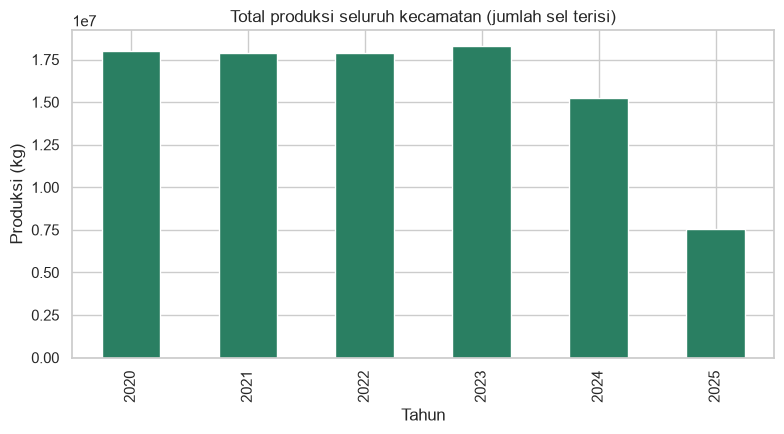

       produksi_total_kg  kecamatan_melapor
tahun                                      
2020          17987380.0                416
2021          17856461.0                416
2022          17883358.0                415
2023          18291400.0                404
2024          15240370.0                348
2025           7559743.0                 50


In [50]:
kab_idx = kab.pivot(index="tahun", columns="komoditas", values="produksi")
base100 = kab_idx / kab_idx.iloc[0] * 100
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
base100.plot(ax=ax[0], marker="o", legend=False); ax[0].set_title("Produksi kabupaten per komoditas (indeks 2020 = 100)")
ax[0].set_xlabel("Tahun"); ax[0].set_ylabel("Indeks produksi")
ax[0].legend(base100.columns, ncol=2, fontsize=7, bbox_to_anchor=(1.0, 1.0), loc="upper left", title="Komoditas")
luas_idx = kab.pivot(index="tahun", columns="komoditas", values="luas"); (luas_idx / luas_idx.iloc[0] * 100).plot(ax=ax[1], marker="o", legend=False)
ax[1].set_title("Luas panen kabupaten per komoditas (indeks 2020 = 100)"); ax[1].set_xlabel("Tahun"); ax[1].set_ylabel("Indeks luas panen")
savefig("08_tren_kabupaten")

yield_pivot = kab.pivot(index="tahun", columns="komoditas", values="produktivitas")
plt.figure(figsize=(11, 6)); sns.heatmap(yield_pivot.T, annot=True, fmt=".2f", cmap="YlGnBu", cbar_kws={"label": "kg per satuan luas"})
plt.title("Produktivitas kabupaten (produksi/luas panen) per komoditas dan tahun"); plt.xlabel("Tahun"); plt.ylabel("Komoditas"); savefig("09_produktivitas_kabupaten")

yoy = kab_idx.pct_change().round(3)
print("Perubahan YoY produksi kabupaten:"); display(yoy)
tot = kec.groupby("tahun").agg(produksi_total_kg=("produksi", "sum"), kecamatan_melapor=("produksi", lambda s: s.notna().sum()))
fig, ax = plt.subplots(figsize=(8, 4.5)); tot["produksi_total_kg"].plot.bar(ax=ax, color="#2a7f62"); ax.set_title("Total produksi seluruh kecamatan (jumlah sel terisi)")
ax.set_xlabel("Tahun"); ax.set_ylabel("Produksi (kg)"); savefig("10_total_produksi_per_tahun")
print(tot)

Geografis (tahun lengkap saja, baris total dikeluarkan)

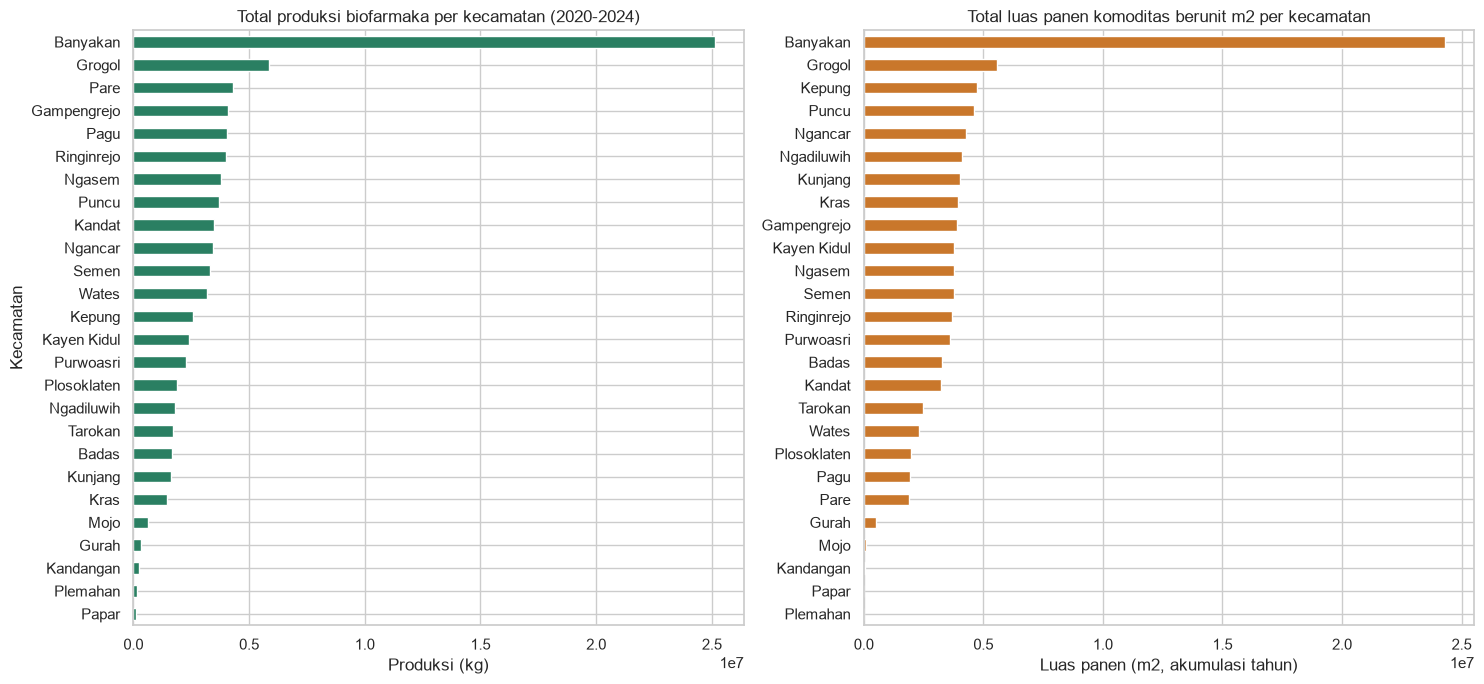

Produksi tertinggi: {'Banyakan': 25114963.0, 'Grogol': 5875967.0, 'Pare': 4300781.0}
Produksi terendah : {'Kandangan': 247907.0, 'Plemahan': 141477.0, 'Papar': 97140.0}
Luas (m2) tertinggi: {'Banyakan': 24304390.0, 'Grogol': 5578755.0, 'Kepung': 4741822.0}
Luas (m2) terendah : {'Kandangan': 57776.0, 'Papar': 26448.0, 'Plemahan': 13766.0}


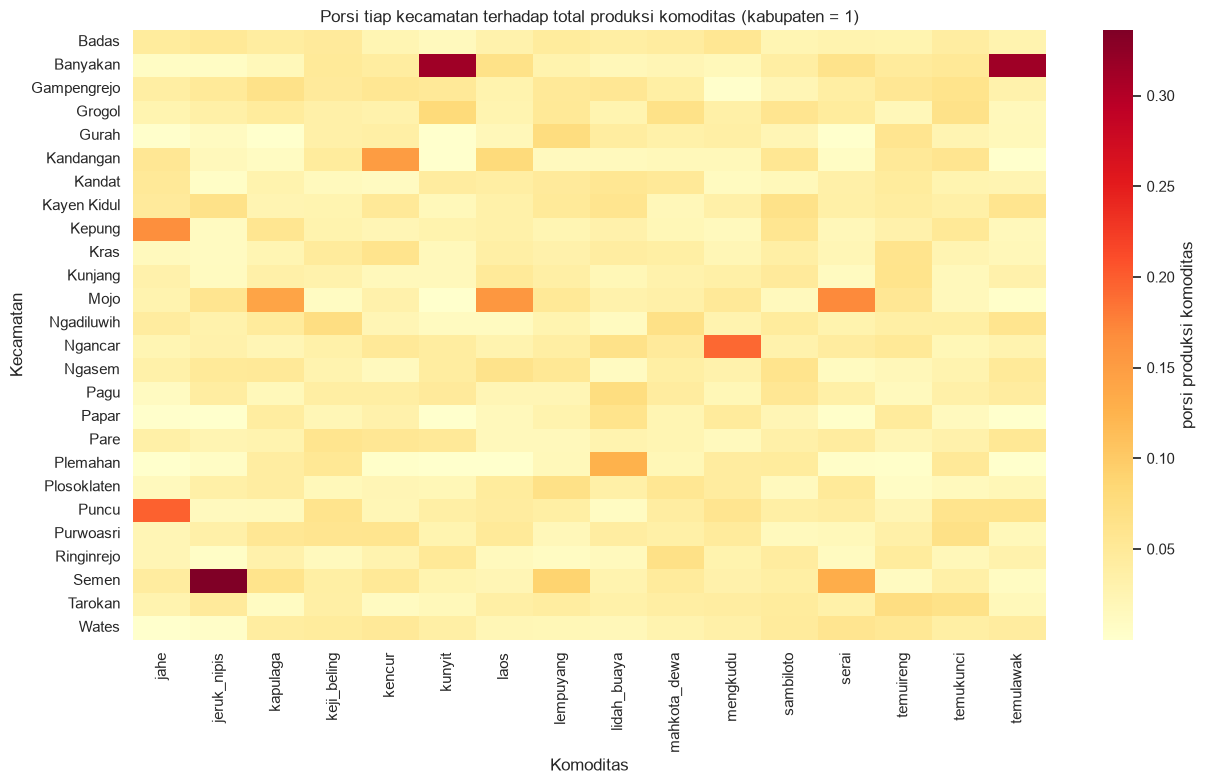

,kecamatan_terbesar,porsi
komoditas,,
jahe,Puncu,0.198
jeruk_nipis,Semen,0.336
kapulaga,Mojo,0.142
keji_beling,Ngadiluwih,0.072
kencur,Kandangan,0.151
kunyit,Banyakan,0.315
laos,Mojo,0.156
lempuyang,Semen,0.090
lidah_buaya,Plemahan,0.127


In [51]:
g_kec = kec[kec["tahun"].isin(COMPLETE_YEARS)]
prod_kec_total = g_kec.groupby("kecamatan")["produksi"].sum().sort_values(ascending=False)
luas_m2 = g_kec[g_kec["unit_luas"] == "m2"].groupby("kecamatan")["luas"].sum().sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(15, 7))
prod_kec_total.sort_values().plot.barh(ax=ax[0], color="#2a7f62"); ax[0].set_title(f"Total produksi biofarmaka per kecamatan ({min(COMPLETE_YEARS)}-{max(COMPLETE_YEARS)})")
ax[0].set_xlabel("Produksi (kg)"); ax[0].set_ylabel("Kecamatan")
luas_m2.sort_values().plot.barh(ax=ax[1], color="#c9772b"); ax[1].set_title("Total luas panen komoditas berunit m2 per kecamatan")
ax[1].set_xlabel("Luas panen (m2, akumulasi tahun)"); ax[1].set_ylabel("")
savefig("11_perbandingan_kecamatan")
print("Produksi tertinggi:", prod_kec_total.head(3).round(0).to_dict()); print("Produksi terendah :", prod_kec_total.tail(3).round(0).to_dict())
print("Luas (m2) tertinggi:", luas_m2.head(3).round(0).to_dict()); print("Luas (m2) terendah :", luas_m2.tail(3).round(0).to_dict())

share = g_kec.pivot_table(index="kecamatan", columns="komoditas", values="produksi", aggfunc="sum")
share = share.div(share.sum(axis=0), axis=1)
plt.figure(figsize=(13, 8)); sns.heatmap(share, cmap="YlOrRd", cbar_kws={"label": "porsi produksi komoditas"})
plt.title("Porsi tiap kecamatan terhadap total produksi komoditas (kabupaten = 1)"); plt.xlabel("Komoditas"); plt.ylabel("Kecamatan"); savefig("12_porsi_kecamatan_komoditas")
top_by_kom = share.idxmax().to_frame("kecamatan_terbesar").join(share.max().round(3).rename("porsi")); display(top_by_kom)

Anomali (MAD modified z-score; hanya ditandai, tidak dihapus)

Jumlah anomali produktivitas (|z|>3.5): 5 | anomali YoY produksi (|Δ|>100%): 0

Anomali per komoditas:


,anom_yield,anom_yoy_prod
komoditas,,
jahe,0,0
jeruk_nipis,0,0
kapulaga,0,0
keji_beling,0,0
kencur,0,0
kunyit,0,0
laos,0,0
lempuyang,0,0
lidah_buaya,0,0


,tahun,kecamatan,komoditas,luas,produksi,produktivitas,z_log_yield
1807,2021,Plemahan,temuireng,27.0,20.0,0.740741,-3.882259
1808,2022,Plemahan,temuireng,29.0,22.0,0.758621,-3.853206
1806,2020,Plemahan,temuireng,25.0,20.0,0.800000,-3.788514
1809,2023,Plemahan,temuireng,28.0,23.0,0.821429,-3.756316
1810,2024,Plemahan,temuireng,30.0,28.0,0.933333,-3.600747


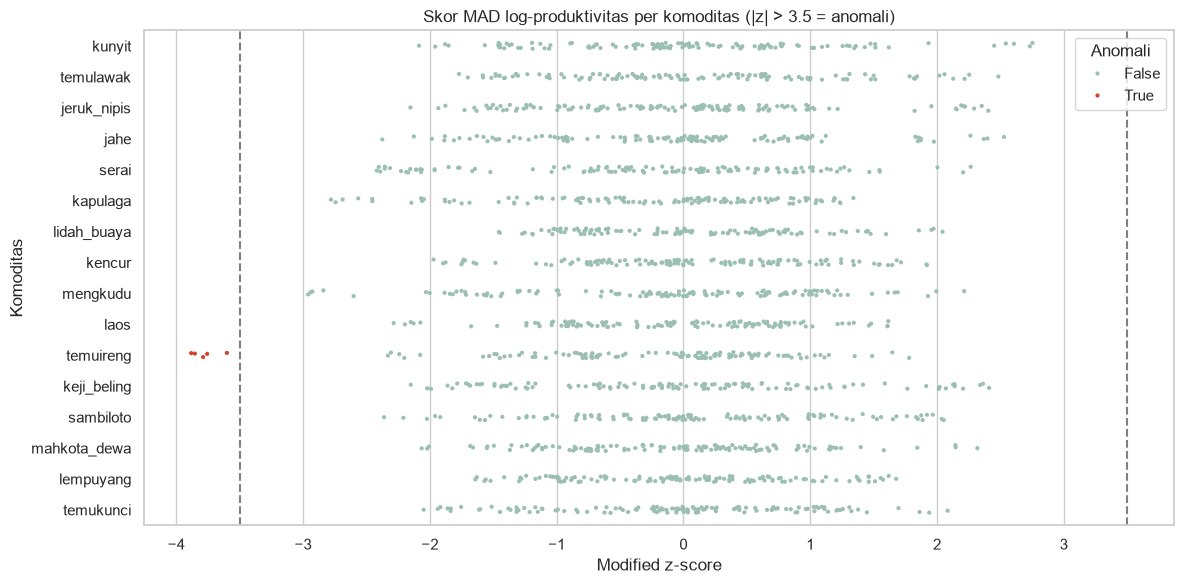


Observasi dengan luas <= 30 satuan: 273 | di antaranya anomali: 5


In [52]:
def mad_z(s):
    med = s.median(); mad = (s - med).abs().median()
    return 0.6745 * (s - med) / mad if mad > 0 else pd.Series(0.0, index=s.index)
kec["z_log_yield"] = np.nan
mask = kec["tahun"].isin(COMPLETE_YEARS) & kec["produktivitas"].gt(0)
kec.loc[mask, "z_log_yield"] = kec[mask].groupby("komoditas")["produktivitas"].transform(lambda s: mad_z(np.log(s)))
kec["anom_yield"] = kec["z_log_yield"].abs() > 3.5        # ambang Iglewicz-Hoaglin
kec["anom_yoy_prod"] = (kec["produksi_yoy"].abs() > 1.0)   # perubahan >100% antar tahun (aturan deskriptif, bukan label)
print("Jumlah anomali produktivitas (|z|>3.5):", int(kec["anom_yield"].sum()), "| anomali YoY produksi (|Δ|>100%):", int(kec["anom_yoy_prod"].sum()))
print("\nAnomali per komoditas:"); display(kec.groupby("komoditas")[["anom_yield", "anom_yoy_prod"]].sum().astype(int))
top_anom = kec[kec["anom_yield"]].reindex(kec[kec["anom_yield"]]["z_log_yield"].abs().sort_values(ascending=False).index).head(15)
display(top_anom[["tahun", "kecamatan", "komoditas", "luas", "produksi", "produktivitas", "z_log_yield"]])
fig, ax = plt.subplots(figsize=(12, 6))
sns.stripplot(data=kec[mask], y="komoditas", x="z_log_yield", hue="anom_yield", palette={False: "#9bbfb0", True: "#d1432f"}, ax=ax, size=3, order=kom_order)
ax.axvline(3.5, ls="--", c="gray"); ax.axvline(-3.5, ls="--", c="gray"); ax.set_title("Skor MAD log-produktivitas per komoditas (|z| > 3.5 = anomali)")
ax.set_xlabel("Modified z-score"); ax.set_ylabel("Komoditas"); ax.legend(title="Anomali"); savefig("13_anomali_produktivitas")
tiny = kec[(kec["luas"] <= 30) & kec["produksi"].notna()]
print(f"\nObservasi dengan luas <= 30 satuan: {len(tiny)} | di antaranya anomali: {int(tiny['anom_yield'].sum())}")

PREPOCESSING

In [53]:
# 1. Dokumentasi preprocessing
doc = []

def log(step, detail, n=None):
    doc.append({
        "langkah": step,
        "detail": detail,
        "jumlah_terdampak": n
    })


# 2. Baca data
log(
    "Baca data",
    "Semua kolom dibaca sebagai teks (encoding utf-8-sig) agar '-' dan '...' terdeteksi",
    sum(d.size for d in raw.values())
)


# 3. Konversi numerik
n_dash = sum(inspection[k]["token_-"] for k in inspection)
n_dots = sum(inspection[k]["token_..."] for k in inspection)

log(
    "Konversi numerik",
    "'-' dan '...' diubah menjadi NaN; jenis penanda disimpan di kolom *_status; nilai asli tidak diubah/diimputasi",
    n_dash + n_dots
)


# 4. Standardisasi kolom
log(
    "Standardisasi kolom",
    "Nama kolom -> snake_case; komoditas -> kunci huruf kecil (mis. 'Laos/Lengkuas' -> 'laos'); kecamatan -> Title Case",
    None
)


# 5. Pemisahan baris total kabupaten
log(
    "Baris total kabupaten",
    f"Baris '{TOTAL_ROW}' dipisah (kec_total) dan tidak dipakai sebagai kecamatan; dipakai untuk rekonsiliasi",
    len(kec_total)
)


# 6. Pemeriksaan duplikasi
log(
    "Duplikasi",
    "Tidak ada duplikat baris/kunci (lihat inspeksi); tidak ada yang dihapus",
    int(sum(v["duplikat_baris"] for v in inspection.values()))
)


# 7. Missing values
log(
    "Missing values",
    "TIDAK diimputasi: pola kosong terkonsentrasi di tahun terbaru (bukan acak); imputasi akan menciptakan data semu dan berisiko memakai informasi masa depan",
    int(kec[["luas", "produksi"]].isna().sum().sum())
)


# 8. Tahun tidak lengkap
log(
    "Tahun tidak lengkap",
    f"Tahun {INCOMPLETE_YEARS} ditandai tahun_lengkap=False dan dikeluarkan dari dataset model",
    int((~kec["tahun"].isin(COMPLETE_YEARS)).sum())
)


# 9. Outlier
log(
    "Outlier",
    "Hanya ditandai (IQR log, MAD z-score); tidak dihapus/winsorize karena skala antarkomoditas berbeda jauh dan penyebabnya belum terverifikasi",
    int(kec["anom_yield"].sum())
)


# 10. Fitur turunan
log(
    "Fitur turunan",
    "produktivitas = produksi/luas; lag1 dan YoY dihitung dari tahun sebelumnya saja",
    None
)


# 11. Satuan
log(
    "Satuan",
    "Luas berunit m2 (kecuali mahkota_dewa, mengkudu, jeruk_nipis = pohon); produksi seluruhnya kg",
    None
)

# 12. Koreksi satuan Serai
log(
    "Koreksi satuan",
    "Luas Serai di file kecamatan berlabel 'Pohon'; dikoreksi menjadi m2 berdasarkan konfirmasi pemberi data (sesuai file agregat)",
    int((kec["komoditas"] == "serai").sum())
)



# Menambahkan kolom status kelengkapan tahun
kec["tahun_lengkap"] = kec["tahun"].isin(COMPLETE_YEARS)


# Memilih kolom untuk dataset bersih
clean_cols = [
    "tahun",
    "kecamatan",
    "komoditas",
    "unit_luas",
    "luas",
    "luas_status",
    "produksi",
    "produksi_status",
    "produktivitas",
    "luas_lag1",
    "produksi_lag1",
    "produktivitas_lag1",
    "luas_yoy",
    "produksi_yoy",
    "produktivitas_yoy",
    "z_log_yield",
    "anom_yield",
    "anom_yoy_prod",
    "tahun_lengkap"
]

# Membuat salinan dataset bersih
clean = kec[clean_cols].copy()


# MENYIMPAN DATASET KE CSV

# Menentukan lokasi penyimpanan:
# AGRIDASH 1.0/data/clean/biofarmaka/
DIRS["clean"] = BASE / "data" / "clean" / "biofarmaka"

# Membuat folder jika belum tersedia
DIRS["clean"].mkdir(parents=True, exist_ok=True)


# Menyimpan dataset kecamatan
clean.to_csv(
    DIRS["clean"] / "biofarmaka_kecamatan_clean.csv",
    index=False,
    encoding="utf-8-sig"
)

# Menyimpan dataset kabupaten
kab.to_csv(
    DIRS["clean"] / "biofarmaka_kabupaten_clean.csv",
    index=False,
    encoding="utf-8-sig"
)

# Menyimpan baris total kabupaten
kec_total.to_csv(
    DIRS["clean"] / "biofarmaka_baris_total_kabupaten.csv",
    index=False,
    encoding="utf-8-sig"
)



# MENAMPILKAN HASIL

# Menampilkan dokumentasi preprocessing
display(pd.DataFrame(doc))

# Konfirmasi penyimpanan
print("=" * 50)
print("BERHASIL MENYIMPAN DATASET BIOFARMAKA")
print("=" * 50)

print("Dataset kecamatan :", clean.shape)
print("Dataset kabupaten :", kab.shape)
print("Baris total       :", kec_total.shape)

print("\nLokasi penyimpanan:")
print(DIRS["clean"])

print("\nFile yang tersimpan:")
print("- biofarmaka_kecamatan_clean.csv")
print("- biofarmaka_kabupaten_clean.csv")
print("- biofarmaka_baris_total_kabupaten.csv")


,langkah,detail,jumlah_terdampak
0,Baca data,Semua kolom dibaca sebagai teks (encoding utf-...,6408.0
1,Konversi numerik,'-' dan '...' diubah menjadi NaN; jenis penand...,933.0
2,Standardisasi kolom,Nama kolom -> snake_case; komoditas -> kunci h...,NaN
3,Baris total kabupaten,Baris 'Kediri' dipisah (kec_total) dan tidak d...,96.0
4,Duplikasi,Tidak ada duplikat baris/kunci (lihat inspeksi...,0.0
5,Missing values,TIDAK diimputasi: pola kosong terkonsentrasi d...,899.0
6,Tahun tidak lengkap,Tahun [2025] ditandai tahun_lengkap=False dan ...,416.0
7,Outlier,"Hanya ditandai (IQR log, MAD z-score); tidak d...",5.0
8,Fitur turunan,produktivitas = produksi/luas; lag1 dan YoY di...,NaN
9,Satuan,"Luas berunit m2 (kecuali mahkota_dewa, mengkud...",NaN


BERHASIL MENYIMPAN DATASET BIOFARMAKA
Dataset kecamatan : (2496, 19)
Dataset kabupaten : (96, 8)
Baris total       : (96, 9)

Lokasi penyimpanan:
C:\Users\Zerlina\Documents\PENS\SEMESTER 5\AGRIDASH 1.0\data\clean\biofarmaka

File yang tersimpan:
- biofarmaka_kecamatan_clean.csv
- biofarmaka_kabupaten_clean.csv
- biofarmaka_baris_total_kabupaten.csv


In [54]:
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)
    print("OK:", d)

OK: C:\Users\Zerlina\Documents\PENS\SEMESTER 5\AGRIDASH 1.0\data\raw
OK: C:\Users\Zerlina\Documents\PENS\SEMESTER 5\AGRIDASH 1.0\data\processed
OK: C:\Users\Zerlina\Documents\PENS\SEMESTER 5\AGRIDASH 1.0\data\model_ready
OK: C:\Users\Zerlina\Documents\PENS\SEMESTER 5\AGRIDASH 1.0\outputs\eda
OK: C:\Users\Zerlina\Documents\PENS\SEMESTER 5\AGRIDASH 1.0\outputs\reports
OK: C:\Users\Zerlina\Documents\PENS\SEMESTER 5\AGRIDASH 1.0\data\clean\biofarmaka


In [55]:
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer

years = sorted(COMPLETE_YEARS)
TRAIN_Y, VAL_Y, TEST_Y = years[:-2], years[-2], years[-1]   # split kronologis, tanpa shuffle
def split_label(y): return "train" if y in TRAIN_Y else "val" if y == VAL_Y else "test" if y == TEST_Y else "tidak_dipakai"
print(f"Split waktu -> train: {TRAIN_Y} | val: {VAL_Y} | test: {TEST_Y}")

obs = clean[clean["tahun_lengkap"]].copy()
# 1) Prediksi produksi: luas tahun berjalan + lag tahun lalu
ml_prod = obs[(obs["luas"] > 0) & (obs["produksi"] > 0)][["tahun", "kecamatan", "komoditas", "unit_luas", "luas", "luas_lag1", "produksi_lag1", "produktivitas_lag1", "produksi"]]
# 2) Prediksi luas panen: hanya informasi tahun sebelumnya
ml_luas = obs[(obs["luas"] > 0)].dropna(subset=["luas_lag1"])[["tahun", "kecamatan", "komoditas", "unit_luas", "luas_lag1", "produksi_lag1", "produktivitas_lag1", "luas"]]
# 3) Sinyal EWS berbasis produksi/produktivitas (deskriptif; bukan label buatan)
ews = obs[["tahun", "kecamatan", "komoditas", "luas", "produksi", "produktivitas", "luas_yoy", "produksi_yoy", "produktivitas_yoy", "anom_yoy_prod"]]
# 4) Seri waktu kabupaten (tren/volatilitas)
ts_kab = kab.copy()
for name, d in {"ml_produksi": ml_prod, "ml_luas_panen": ml_luas, "ews_sinyal_produksi": ews}.items():
    d = d.copy(); d.insert(1, "split", d["tahun"].map(split_label)); d.to_csv(DIRS["model_ready"] / f"{name}.csv", index=False)
    print(f"{name}: {d.shape} | " + ", ".join(f"{k}={v}" for k, v in d["split"].value_counts().items()))
ts_kab.to_csv(DIRS["model_ready"] / "timeseries_kabupaten.csv", index=False)

def build_preprocessor(num_cols, cat_cols):
    num = Pipeline([("impute", SimpleImputer(strategy="median")),     # median dihitung dari train saja
                    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")), ("scale", StandardScaler())])
    return ColumnTransformer([("num", num, num_cols), ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)])

for name, target, d in [("ml_produksi", "produksi", ml_prod), ("ml_luas_panen", "luas", ml_luas)]:
    feats_num = [c for c in d.columns if c not in ("kecamatan", "komoditas", "unit_luas", "tahun", target)] + ["tahun"]
    feats_cat = ["kecamatan", "komoditas"]
    tr = d[d["tahun"].isin(TRAIN_Y)]; va = d[d["tahun"] == VAL_Y]; te = d[d["tahun"] == TEST_Y]
    pre = build_preprocessor(feats_num, feats_cat).fit(tr[feats_num + feats_cat])   # fit hanya di train
    Xtr, Xva, Xte = (pre.transform(x[feats_num + feats_cat]) for x in (tr, va, te))
    joblib.dump(pre, DIRS["model_ready"] / f"preprocessor_{name}.joblib")
    print(f"{name}: X_train={Xtr.shape}, X_val={Xva.shape}, X_test={Xte.shape} | target={target} (disarankan model pada log1p(target))")

Split waktu -> train: [2020, 2021, 2022] | val: 2023 | test: 2024
ml_produksi: (1926, 10) | train=1247, val=392, test=287
ml_luas_panen: (1578, 9) | train=832, val=404, test=342
ews_sinyal_produksi: (2080, 11) | train=1248, val=416, test=416
ml_produksi: X_train=(1247, 47), X_val=(392, 47), X_test=(287, 47) | target=produksi (disarankan model pada log1p(target))
ml_luas_panen: X_train=(832, 46), X_val=(404, 46), X_test=(342, 46) | target=luas (disarankan model pada log1p(target))


Laporan

In [57]:
desc = clean.groupby("komoditas")[["luas", "produksi", "produktivitas"]].describe().round(3)
desc.to_csv(DIRS["reports"] / "statistik_deskriptif_per_komoditas.csv")
clean.describe(include="all").T.to_csv(DIRS["reports"] / "statistik_deskriptif_keseluruhan.csv")
pd.DataFrame(doc).to_csv(DIRS["reports"] / "dokumentasi_preprocessing.csv", index=False)
pd.DataFrame(inspection).T.astype(str).to_csv(DIRS["reports"] / "ringkasan_inspeksi_dataset.csv")
unit_conflict.to_csv(DIRS["reports"] / "konflik_satuan.csv", index=False)
display(pd.DataFrame(doc))
print("\nIsi folder output:")
for d in DIRS.values():
    print(d, "->", sorted(p.name for p in d.glob("*")))

,langkah,detail,jumlah_terdampak
0,Baca data,Semua kolom dibaca sebagai teks (encoding utf-...,6408.0
1,Konversi numerik,'-' dan '...' diubah menjadi NaN; jenis penand...,933.0
2,Standardisasi kolom,Nama kolom -> snake_case; komoditas -> kunci h...,NaN
3,Baris total kabupaten,Baris 'Kediri' dipisah (kec_total) dan tidak d...,96.0
4,Duplikasi,Tidak ada duplikat baris/kunci (lihat inspeksi...,0.0
5,Missing values,TIDAK diimputasi: pola kosong terkonsentrasi d...,899.0
6,Tahun tidak lengkap,Tahun [2025] ditandai tahun_lengkap=False dan ...,416.0
7,Outlier,"Hanya ditandai (IQR log, MAD z-score); tidak d...",5.0
8,Fitur turunan,produktivitas = produksi/luas; lag1 dan YoY di...,NaN
9,Satuan,"Luas berunit m2 (kecuali mahkota_dewa, mengkud...",NaN



Isi folder output:
C:\Users\Zerlina\Documents\PENS\SEMESTER 5\AGRIDASH 1.0\data\raw -> ['Luas_Panen_Biofarmaka.csv', 'Luas_Panen_Biofarmaka_per_kecamatan.csv', 'Total_Produksi_Biofarmaka.csv', 'Total_Produksi_Biofarmaka_per_kecamatan.csv']
C:\Users\Zerlina\Documents\PENS\SEMESTER 5\AGRIDASH 1.0\data\processed -> []
C:\Users\Zerlina\Documents\PENS\SEMESTER 5\AGRIDASH 1.0\data\model_ready -> ['ews_sinyal_produksi.csv', 'ml_luas_panen.csv', 'ml_produksi.csv', 'preprocessor_ml_luas_panen.joblib', 'preprocessor_ml_produksi.joblib', 'timeseries_kabupaten.csv']
C:\Users\Zerlina\Documents\PENS\SEMESTER 5\AGRIDASH 1.0\outputs\eda -> []
C:\Users\Zerlina\Documents\PENS\SEMESTER 5\AGRIDASH 1.0\outputs\reports -> ['dokumentasi_preprocessing.csv', 'konflik_satuan.csv', 'ringkasan_inspeksi_dataset.csv', 'statistik_deskriptif_keseluruhan.csv', 'statistik_deskriptif_per_komoditas.csv']
C:\Users\Zerlina\Documents\PENS\SEMESTER 5\AGRIDASH 1.0\data\clean\biofarmaka -> ['biofarmaka_baris_total_kabupaten.c